# Jude 2026 intended speech: exploring the source data

<img src="assets/experiment_abstract.png" alt="experiment overview" width="500">

A local walk-through of the Dryad `.mat` source of the anarthria intended-speech iBCI dataset (participant **T17**), read through the dataset `utils`. The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file. The files live under `<NEURALSHED_DATA_ROOT>/jude_2026_speech/data/Jude2026IntendedSpeech/t17/`, one folder per session.

**What's here:** 14 sessions (post-implant days 25-166), 140 `.mat` blocks (38.6 GB). Each block holds:
- 10 ms-binned threshold crossings and spike-band power from six 64-channel Utah arrays in left precentral gyrus
- the cued language unit per trial
- trial timing as NSP timestamps
- 30 kHz microphone audio

Out of the 140 block files:
- 121 task blocks containing 5,114 trials
- 19 reference, diagnostic, aborted or unreadable files, which the Study skips

**Experimental tasks:**
| Task | What T17 did | Blocks / trials |
|---|---|---:|
| Orofacial movements | Attempt 12 jaw, lip and tongue movements, four "Say" syllables, or rest | 5 / 170 |
| Isolated phonemes | Attempt the highlighted phoneme of cues such as "Bah" or "thOUGHt", 39 phonemes plus rest | 9 / 720 |
| Individual words | Attempt one of 50 communication words | 9 / 450 |
| 50-word sentences, open loop | Attempt sentences composed from the restricted vocabulary, with no decoder feedback | 18 / 720 |
| 50-word sentences, closed loop | Same task, with online decoded text and synthesized-voice feedback | 8 / 320 |
| 125k-word sentences, open loop | Attempt sentences from a much larger vocabulary, without feedback | 51 / 1,982 |
| 125k-word sentences, closed loop | Larger-vocabulary online decoding with text and speech feedback | 16 / 502 |
| Phased task | Process the same phoneme, word or sentence by reading, imagining and then attempting it | 5 / 250 |

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from neuralshed.datasets.jude_2026_speech import utils as u
from neuralshed.datasets.jude_2026_speech.study import Jude2026IntendedSpeech
from neuralshed.datasets.utils import dataset_dir

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

# reads ./.env into os.environ
load_dotenv()

s = Jude2026IntendedSpeech(path=dataset_dir("jude_2026_speech") / "data")
s.download()
t17 = s.path / "t17"  # one folder per session
print("data dir:", s.path)
print("bins:", u.NEURAL_BIN_SIZE_MS, "ms /", u.FS_NEURAL, "Hz | audio:", u.AUDIO_FS, "Hz")
print("arrays:", u.N_ARRAYS, "x", u.CHANNELS_PER_ARRAY, "ch ->", u.N_ELECTRODES_FULL, "columns, or", u.N_ELECTRODES_DECODER, "on the three sessions recorded without the 6d arrays")

2026-10-15 12:09:32 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/jude_2026_speech/data/Jude2026IntendedSpeech.


2026-10-15 12:09:58 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/jude_2026_speech/data/Jude2026IntendedSpeech (skipped 0 non-owned items).


data dir: /Volumes/seagate_0/tether/datasets/jude_2026_speech/data/Jude2026IntendedSpeech
bins: 10 ms / 100 Hz | audio: 30000 Hz
arrays: 6 x 64 ch -> 384 columns, or 256 on the three sessions recorded without the 6d arrays


## 1. Sessions and blocks

One row per session: date, post-implant day, recorded channel count (**384** on eleven sessions, **256** on the three mid-April sessions recorded without the 6d arrays), task blocks, excluded files, trials and the task families present. The task family of each block comes from the Dryad block tables (`utils.SESSION_BLOCKS`), not from the file's `block_description` field.

In [2]:
rows = []
for session in u.list_sessions(t17):
    catalogued = u.SESSION_BLOCKS[session]
    excluded = u.EXCLUDED_BLOCKS.get(session, {})
    n_trials = 0
    for block in catalogued:
        n_trials += len(u.get_trials(u.block_path(session, block, t17)))
    rows.append(
        {
            "session": session,
            "date": u.session_date(session),
            "post_implant_day": u.post_implant_day(session),
            "n_ch": u.session_n_channels(session),
            "task_blocks": len(catalogued),
            "excluded": len(excluded),
            "n_trials": n_trials,
            "tasks": ", ".join(sorted(set(catalogued.values()))),
        }
    )
sessions_df = pd.DataFrame(rows)
print(len(sessions_df), "sessions,", sessions_df.task_blocks.sum(), "task blocks,", sessions_df.excluded.sum(), "excluded files,", sessions_df.n_trials.sum(), "trials")
sessions_df

14 sessions, 121 task blocks, 19 excluded files, 5114 trials


,session,date,post_implant_day,n_ch,task_blocks,excluded,n_trials,tasks
0,t17.2024.03.25,2024-03-25,25,384,14,0,890,"orofacial, phoneme"
1,t17.2024.03.26,2024-03-26,26,384,14,1,650,"sentence_50w_cl, sentence_50w_ol, word"
2,t17.2024.04.02,2024-04-02,33,384,13,1,463,"sentence_125k_cl, sentence_125k_ol, sentence_50w_cl, sentence_50w_ol"
3,t17.2024.04.15,2024-04-15,46,256,9,0,360,sentence_125k_ol
4,t17.2024.04.16,2024-04-16,47,256,5,0,200,sentence_125k_ol
5,t17.2024.04.17,2024-04-17,48,256,9,2,273,"sentence_125k_cl, sentence_125k_ol"
6,t17.2024.05.06,2024-05-06,67,384,9,2,330,sentence_125k_ol
7,t17.2024.05.07,2024-05-07,68,384,10,2,400,"sentence_125k_cl, sentence_125k_ol"
8,t17.2024.05.13,2024-05-13,74,384,2,0,80,sentence_125k_ol
9,t17.2024.05.14,2024-05-14,75,384,7,2,258,"sentence_125k_cl, sentence_125k_ol"


### Excluded blocks

Every file the Study skips, with the reason recorded in `utils.EXCLUDED_BLOCKS`: the reference block of each later session (one `DO_NOTHING` trial used to fit the referencing and thresholds), the diagnostic speech blocks, one aborted word block and the one file that cannot be read.

In [3]:
rows = []
for session, blocks in u.EXCLUDED_BLOCKS.items():
    for block, reason in blocks.items():
        path = u.block_path(session, block, t17)
        rows.append(
            {
                "session": session,
                "block": block,
                "size_MB": round(path.stat().st_size / 1e6, 1),
                "reason": reason,
            }
        )
excluded_df = pd.DataFrame(rows)
print(len(excluded_df), "excluded files")
excluded_df

19 excluded files


,session,block,size_MB,reason
0,t17.2024.03.26,18,8.0,"aborted word block, 2 trials"
1,t17.2024.04.02,0,204.5,"diagnostic speech block over 8 reference cues, not a task block"
2,t17.2024.04.17,0,189.9,"diagnostic speech block over 8 reference cues, not a task block"
3,t17.2024.04.17,9,72.1,"diagnostic speech block over 8 reference cues, not a task block"
4,t17.2024.05.06,0,97.1,"reference block, one DO_NOTHING trial, used to fit LRR and thresholds"
5,t17.2024.05.06,3,97.1,"reference block, one DO_NOTHING trial, used to fit LRR and thresholds"
6,t17.2024.05.07,0,97.1,"reference block, one DO_NOTHING trial, used to fit LRR and thresholds"
7,t17.2024.05.07,6,97.1,"reference block, one DO_NOTHING trial, used to fit LRR and thresholds"
8,t17.2024.05.14,0,97.1,"reference block, one DO_NOTHING trial, used to fit LRR and thresholds"
9,t17.2024.05.14,4,97.1,"reference block, one DO_NOTHING trial, used to fit LRR and thresholds"


## 2. One block up close

A 125k-word **open-loop sentence** block from `t17.2024.04.17`, a 256-channel session. The two neural feature streams share one `(n_bins, n_ch)` timebase in file column order. Counts are `int16`, spike-band power is `float32`, and neither is normalized.

In [4]:
session = "t17.2024.04.17"
block = 4
path = u.block_path(session, block, t17)
print(f"{session} block {block} [{u.task_of(session, block)}] n_ch={u.n_channels(path)}")

tx, sbp = u.get_neural(path)
print("threshold_crossings:", tx.shape, tx.dtype, "| range", int(tx.min()), "-", int(tx.max()))
print("spike_band_power   :", sbp.shape, sbp.dtype, "| mean %.1f" % sbp.mean())

dur_s = tx.shape[0] * u.NEURAL_BIN_SIZE_MS / 1000
print(f"block duration: {dur_s:.0f} s ({tx.shape[0]} bins @ {u.FS_NEURAL} Hz)")

t17.2024.04.17 block 4 [sentence_125k_ol] n_ch=256


threshold_crossings: (63720, 256) int16 | range 0 - 10
spike_band_power   : (63720, 256) float32 | mean 358.2
block duration: 637 s (63720 bins @ 100 Hz)


### Per-array channel layout

`utils.to_study_order` permutes the file columns into Study order, one contiguous block of 64 columns per array in `utils.ARRAY_ORDER` (6v, 55b, 6d). The 256-channel sessions hold the first four arrays. The table lists each array's Study columns, its file columns for this session and the mean of both streams over it.

In [5]:
# file order -> Study order, one contiguous block of 64 columns per array
tx = u.to_study_order(tx, session)
sbp = u.to_study_order(sbp, session)
file_cols = u.channel_order(session)

rows = []
for name, (lo, hi) in u.array_channels(session).items():
    rows.append(
        {
            "array": name,
            "study_cols": f"{lo}-{hi - 1}",
            "file_cols": f"{file_cols[lo]}-{file_cols[hi - 1]}",
            "mean_TX_per_bin": round(float(tx[:, lo:hi].mean()), 3),
            "mean_SBP": round(float(sbp[:, lo:hi].mean()), 1),
        }
    )
pd.DataFrame(rows)

,array,study_cols,file_cols,mean_TX_per_bin,mean_SBP
0,ventral_6v,0-63,0-63,0.173,421.5
1,dorsal_6v,64-127,64-127,0.130,512.7
2,ventral_55b,128-191,128-191,0.082,242.4
3,dorsal_55b,192-255,192-255,0.087,256.0


### Channel eras

The file column order changed after `t17.2024.04.02`, and the three mid-April sessions recorded only the four 6v and 55b arrays. `utils.channel_order` gives the file column of each Study column for a session, so the same electrode sits in the same Study column in every era. The per-channel median spike-band power of one block per era, in Study order, shows the six arrays lining up.

,early,256-channel,late
ventral_6v,192-255,0-63,0-63
dorsal_6v,128-191,64-127,64-127
ventral_55b,320-383,128-191,128-191
dorsal_55b,256-319,192-255,192-255
ventral_6d,0-63,absent,256-319
dorsal_6d,64-127,absent,320-383


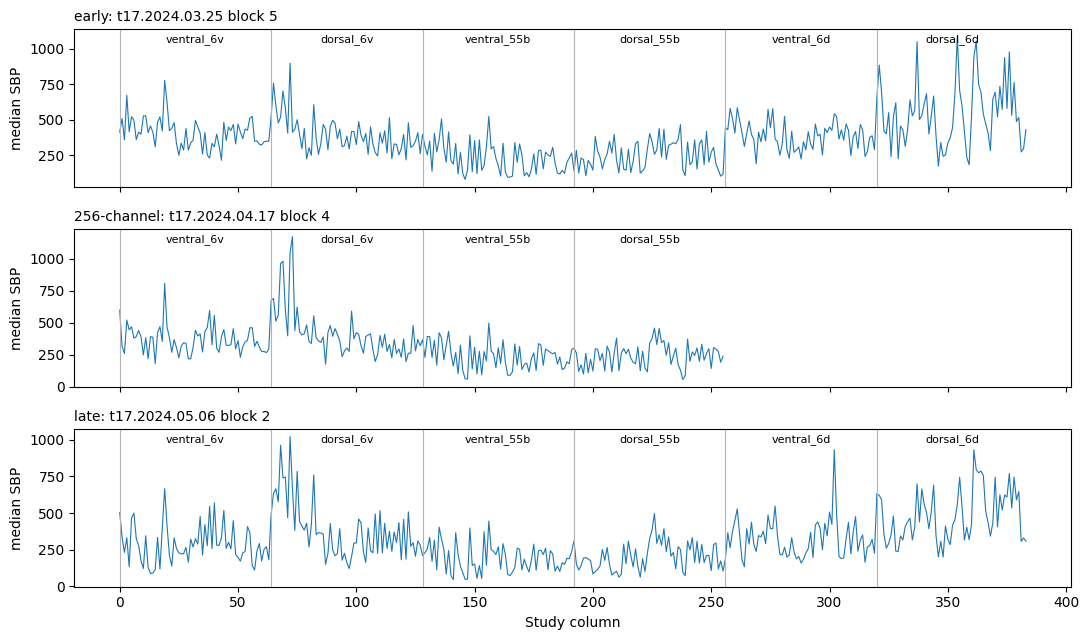

In [6]:
era_blocks = {
    "early": ("t17.2024.03.25", 5),
    "256-channel": ("t17.2024.04.17", 4),
    "late": ("t17.2024.05.06", 2),
}

columns = {}
for era, (sess, _) in era_blocks.items():
    order = u.channel_order(sess)
    columns[era] = {name: f"{order[lo]}-{order[hi - 1]}" for name, (lo, hi) in u.array_channels(sess).items()}
display(pd.DataFrame(columns).reindex(list(u.ARRAY_ORDER)).fillna("absent"))

fig, axes = plt.subplots(len(era_blocks), 1, figsize=(11, 6.5), sharex=True)
for ax, (era, (sess, blk)) in zip(axes, era_blocks.items()):
    _, sbp_era = u.get_neural(u.block_path(sess, blk, t17))
    median = np.median(u.to_study_order(sbp_era, sess), axis=0)
    ax.plot(median, lw=0.8)
    top = ax.get_ylim()[1]
    for name, (lo, hi) in u.array_channels(sess).items():
        ax.axvline(lo, color="0.7", lw=0.8)
        ax.text((lo + hi) / 2, top * 0.92, name, ha="center", fontsize=8)
    ax.set_ylabel("median SBP")
    ax.set_title(f"{era}: {sess} block {blk}", loc="left", fontsize=10)
axes[-1].set_xlabel("Study column")
plt.tight_layout()
plt.show()

### Trial table

One row per cue. The cued text is the decoding target. `trial_start_ns`, `go_cue_ns` and `trial_end_ns` are NSP timestamps in nanoseconds that place each trial on the neural bins. `paused` and `timed_out` mark interrupted trials, which the Study emits with `success=False`.

In [7]:
trials = u.get_trials(path)
print(len(trials), "trials |", int(trials.paused.sum()), "paused,", int(trials.timed_out.sum()), "timed out")
print("columns:", list(trials.columns))
trials[["cue", "delay_ms", "iti_ms", "trial_start_ns", "go_cue_ns", "trial_end_ns"]].head(8)

40 trials | 0 paused, 0 timed out
columns: ['cue', 'delay_ms', 'iti_ms', 'paused', 'timed_out', 'go_cue_ns', 'trial_end_ns', 'trial_start_ns']


,cue,delay_ms,iti_ms,trial_start_ns,go_cue_ns,trial_end_ns
0,Sales I find are a pain.,7016.0,0.0,1.712350e+18,1.712350e+18,1.712350e+18
1,"But again, you know that's not the Treasury's call.",7128.0,0.0,1.712350e+18,1.712350e+18,1.712350e+18
2,Cohen has denied any collusion with Russia.,7045.0,0.0,1.712350e+18,1.712350e+18,1.712350e+18
3,That's something.,7040.0,0.0,1.712350e+18,1.712350e+18,1.712350e+18
4,I think it's important.,7192.0,0.0,1.712350e+18,1.712350e+18,1.712350e+18
5,If you haven't done it in a while.,7149.0,0.0,1.712350e+18,1.712350e+18,1.712350e+18
6,His treasures come with answers.,7095.0,0.0,1.712350e+18,1.712350e+18,1.712350e+18
7,You're invading their border.,7121.0,0.0,1.712350e+18,1.712350e+18,1.712350e+18


### Trial timing across task families

One block per non-phased family. The delay runs from trial start to the go cue, the go period from the go cue to the trial end, and the gap from a trial end to the next trial start. Open-loop trials follow each other without a gap, closed-loop trials leave seconds for the decoder output and the text-to-speech playback. The `delay_duration_ms` field reads 200 in the August 50-word sentence blocks while the timestamps measure 5-6 s (the field and the timestamps agree in every other block), so the Study windows every event from the NSP timestamps.

In [8]:
first_block = {}
for sess, blocks in u.SESSION_BLOCKS.items():
    for blk, family in blocks.items():
        first_block.setdefault(family, (sess, blk))

timing_blocks = {family: blk for family, blk in first_block.items() if not family.startswith("phased")}
timing_blocks["sentence_50w_ol (August)"] = ("t17.2024.08.12", 1)
timing_blocks["sentence_50w_cl (August)"] = ("t17.2024.08.13", 6)

rows = []
for family, (sess, blk) in timing_blocks.items():
    tr = u.get_trials(u.block_path(sess, blk, t17))
    delay_s = (tr.go_cue_ns - tr.trial_start_ns) / 1e9
    go_s = (tr.trial_end_ns - tr.go_cue_ns) / 1e9
    gap_s = (tr.trial_start_ns.values[1:] - tr.trial_end_ns.values[:-1]) / 1e9
    rows.append(
        {
            "task_family": family,
            "block": f"{sess} b{blk}",
            "n_trials": len(tr),
            "delay_field_ms": int(tr.delay_ms.median()),
            "delay_s": round(float(delay_s.median()), 2),
            "go_period_s": round(float(go_s.median()), 2),
            "gap_s": round(float(np.median(gap_s)), 2),
        }
    )
pd.DataFrame(rows)

,task_family,block,n_trials,delay_field_ms,delay_s,go_period_s,gap_s
0,phoneme,t17.2024.03.25 b5,80,2500,2.50,2.00,0.00
1,orofacial,t17.2024.03.25 b14,34,2500,2.50,2.00,0.00
2,word,t17.2024.03.26 b10,50,2500,2.50,3.93,0.00
3,sentence_50w_ol,t17.2024.03.26 b23,40,4500,4.50,5.88,0.00
4,sentence_50w_cl,t17.2024.03.26 b27,40,4500,4.50,7.50,3.45
5,sentence_125k_ol,t17.2024.04.02 b6,40,4500,4.50,11.17,0.00
6,sentence_125k_cl,t17.2024.04.02 b13,11,4500,4.50,11.49,13.59
7,sentence_50w_ol (August),t17.2024.08.12 b1,40,200,6.18,7.80,0.00
8,sentence_50w_cl (August),t17.2024.08.13 b6,40,200,5.83,8.46,5.93


### Neural features for one trial

Slice one trial from the go cue to the trial end through the NSP timestamps and show both streams over the Study columns, the view the decoder sees.

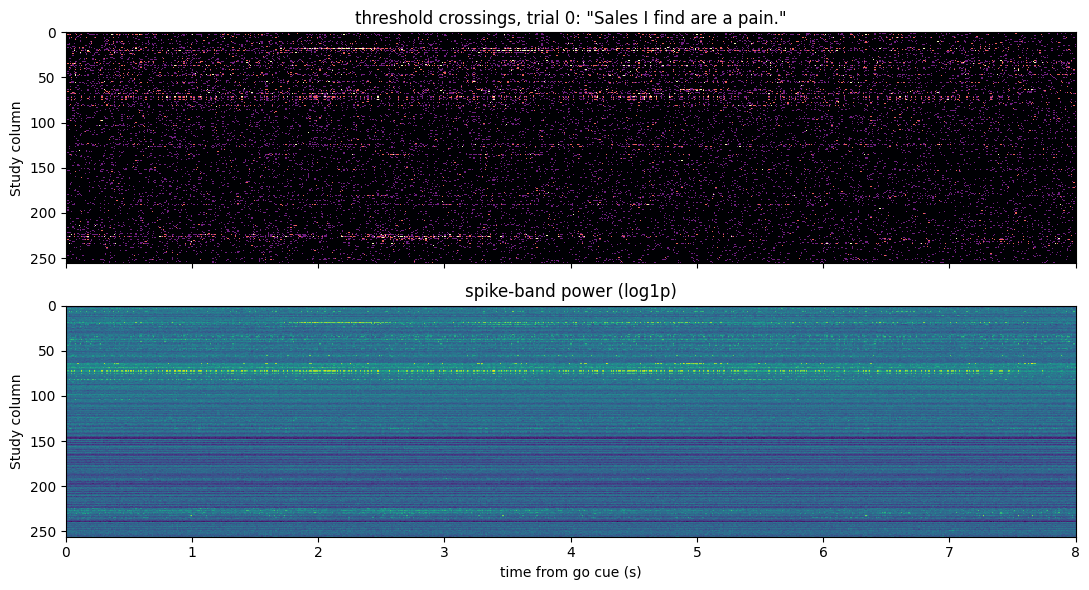

trial spans bins 702-1503 (8.0 s)


In [9]:
bin_t = u.get_bin_times_ns(path)
ti = 0
s0, s1 = u.trial_window(bin_t, trials.go_cue_ns[ti], trials.trial_end_ns[ti])
tx_tr = tx[s0:s1]
sbp_tr = sbp[s0:s1]
t = np.arange(s1 - s0) * u.NEURAL_BIN_SIZE_MS / 1000

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].imshow(tx_tr.T, aspect="auto", interpolation="none", extent=[0, t[-1], tx_tr.shape[1], 0], clim=(0, 3), cmap="magma")
ax[0].set_ylabel("Study column")
ax[0].set_title(f"threshold crossings, trial {ti}: \"{trials.cue[ti]}\"")
ax[1].imshow(np.log1p(sbp_tr.T), aspect="auto", interpolation="none", extent=[0, t[-1], sbp_tr.shape[1], 0], cmap="viridis")
ax[1].set_ylabel("Study column")
ax[1].set_xlabel("time from go cue (s)")
ax[1].set_title("spike-band power (log1p)")
plt.tight_layout()
plt.show()
print(f"trial spans bins {s0}-{s1} ({(s1 - s0) * u.NEURAL_BIN_SIZE_MS / 1000:.1f} s)")

## 3. Microphone audio (30 kHz)

Audio is recorded per block and time-aligned with the neural bins. T17 is anarthric, so it captures breathing and effort rather than intelligible speech. The waveform is downsampled for plotting only.

audio: (19116030,) int16 @ 30000 Hz = 637 s


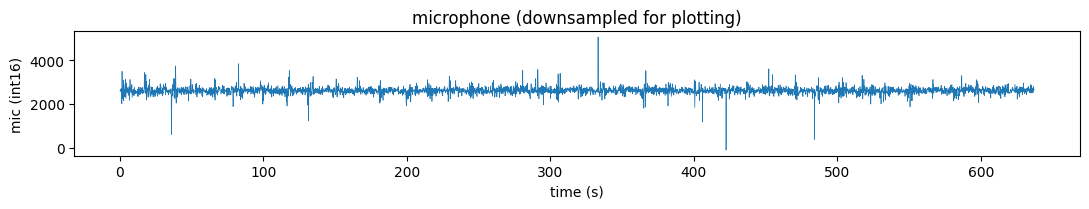

In [10]:
audio, fs = u.get_audio(path)
secs = audio.size / fs
print(f"audio: {audio.shape} int16 @ {fs} Hz = {secs:.0f} s")

step = max(1, audio.size // 4000)
plt.figure(figsize=(11, 2.2))
plt.plot(np.arange(0, audio.size, step) / fs, audio[::step], lw=0.5)
plt.xlabel("time (s)")
plt.ylabel("mic (int16)")
plt.title("microphone (downsampled for plotting)")
plt.tight_layout()
plt.show()

## 4. Cues across task families

The cue string changes shape by task: orofacial movement instructions, nonsense syllables that highlight a phoneme, uppercase single words and full sentences. `utils` holds the alphabets: `PHONEME_CUES` maps each syllable to its ARPAbet phoneme, `REST_CUES`, `OROFACIAL_CUES` and `SAY_CUES` cover the movement blocks, `WORD_CUES` is the 50-word vocabulary and `PHONE_DEF_SIL` the 40 phoneme classes (39 plus silence) the online decoder emitted, before the CTC blank.

In [11]:
rows = []
for family, (sess, blk) in first_block.items():
    tr = u.get_trials(u.block_path(sess, blk, t17))
    cues = sorted(set(tr.cue))
    rows.append(
        {
            "task_family": family,
            "block": f"{sess} b{blk}",
            "n_trials": len(tr),
            "distinct_cues": len(cues),
            "examples": cues[:3],
        }
    )
display(pd.DataFrame(rows))

print("phoneme cue -> ARPAbet target (utils.PHONEME_CUES):")
print("  " + "  ".join(f"{cue}={sym}" for cue, sym in u.PHONEME_CUES.items()))
print("rest cues:", u.REST_CUES)
print("orofacial cues:", u.OROFACIAL_CUES)
print("syllable cues:", u.SAY_CUES)
print("50-word vocabulary:", " ".join(u.WORD_CUES))
print("PHONE_DEF_SIL (40):", " ".join(u.PHONE_DEF_SIL))

,task_family,block,n_trials,distinct_cues,examples
0,phoneme,t17.2024.03.25 b5,80,40,"[Bah, Chah, DO_NOTHING]"
1,orofacial,t17.2024.03.25 b14,34,17,"[Clench jaw, Do Nothing, Frown]"
2,word,t17.2024.03.26 b10,50,50,"[AM, ARE, BAD]"
3,sentence_50w_ol,t17.2024.03.26 b23,40,40,"[Are they going up?, Computer is bad., Do you have success?]"
4,sentence_50w_cl,t17.2024.03.26 b27,40,40,"[Are you it?, Do it like that., Do not clean it up.]"
5,sentence_125k_ol,t17.2024.04.02 b6,40,40,"[A little bit with refugees., A matter of choice., An economy car right now.]"
6,sentence_125k_cl,t17.2024.04.02 b13,11,11,"[Civil things that clog the courts., Forms for things., I hope your baby likes his toy.]"
7,phased_phoneme,t17.2024.05.23 b1,50,10,"[Ah, Dah, Gah]"
8,phased_word,t17.2024.05.23 b2,50,10,"[Cheldgup, Comfortable, Computer]"
9,phased_short_sentence,t17.2024.05.23 b3,50,10,"[Bring it up closer., Faith hungry computer., I like my music.]"


phoneme cue -> ARPAbet target (utils.PHONEME_CUES):
  Pah=P  Bah=B  Mah=M  Fah=F  Vah=V  Thah=TH  THe=DH  Tah=T  Dah=D  Nah=N  Sah=S  Zah=Z  Chah=CH  Jah=JH  Shah=SH  Zhah=ZH  Ngah=NG  Kah=K  Gah=G  Yah=Y  Lah=L  Rah=R  Wah=W  Hah=HH  chOIce=OY  gOAt=OW  thOUGHt=AO  lOt=AA  mOUth=AW  prIce=AY  trAp=AE  drEss=EH  fAce=EY  flEEce=IY  kIt=IH  strUt=AH  gOOse=UW  LettER=ER  fOOt=UH  Ah=AA  Oy=OY
rest cues: ('DO_NOTHING', 'Do Nothing')
orofacial cues: ('Clench jaw', 'Open jaw', 'Frown', 'Smile', 'Pucker lips', 'Tuck lips', 'Hum a HIGH frequency', 'Hum a LOW frequency', 'Push your tongue behind your LOWER teeth', 'Push your tongue behind your UPPER teeth', 'Push tongue to FRONT roof of your mouth', 'Push tongue to BACK roof of your mouth')
syllable cues: {'Say Dah': 'D AA', 'Say Fah': 'F AA', 'Say Jah': 'JH AA', 'Say Yah': 'Y AA'}
50-word vocabulary: AM ARE BAD BRING CLEAN CLOSER COMFORTABLE COMING COMPUTER DO FAITH FAMILY FEEL GLASSES GOING GOOD GOODBYE HAVE HELLO HELP HERE HOPE HOW HUNGRY 

## 5. The phased task (read, imagined, attempted)

Session **2024.05.23** runs the three-phase paradigm: each trial cues a language unit, then the participant **reads** it, **imagines** speaking it and **attempts** to vocalize it. Per-trial NSP markers delimit the phases (`utils.PHASE_WINDOWS`), and `phase_windows()` returns the neural-bin range of each.

In [12]:
ps = "t17.2024.05.23"
pb = 1  # phased phonemes
pp = u.block_path(ps, pb, t17)
ptr = u.get_trials(pp)
pbin = u.get_bin_times_ns(pp)
print(f"{ps} block {pb} [{u.task_of(ps, pb)}] {len(ptr)} trials")
print("marker columns:", [c for c in ptr.columns if c.endswith("_ns")])

w = u.phase_windows(ptr, pbin, 0)
for phase, (a, b) in w.items():
    print(f"  trial 0 {phase:>9}: bins {a:>6}-{b:<6} ({(b - a) * u.NEURAL_BIN_SIZE_MS / 1000:5.1f} s)")

t17.2024.05.23 block 1 [phased_phoneme] 50 trials
marker columns: ['cue_presentation_ns', 'go_cue_ns', 'imagined_delay_ns', 'imagined_go_period_ns', 'intertrial_start_ns', 'trial_end_ns', 'trial_start_ns', 'vocalized_delay_start_ns', 'vocalized_go_cue_ns']
  trial 0      read: bins    200-450    (  2.5 s)
  trial 0  imagined: bins    650-900    (  2.5 s)
  trial 0 attempted: bins   1101-1351   (  2.5 s)


In [13]:
# mean spike-band power per phase over the first ten trials
ptx, psbp = u.get_neural(pp)
phase_means = {ph: [] for ph in u.PHASE_WINDOWS}
for ti in range(min(10, len(ptr))):
    for ph, (a, b) in u.phase_windows(ptr, pbin, ti).items():
        if b > a:
            phase_means[ph].append(psbp[a:b].mean())
for ph, vals in phase_means.items():
    print(f"  {ph:>9}: mean SBP {np.mean(vals):7.1f} over {len(vals)} trials")

       read: mean SBP   417.3 over 10 trials
   imagined: mean SBP   430.3 over 10 trials
  attempted: mean SBP   441.2 over 10 trials


## 6. Online decoder configuration

Closed-loop blocks store what the online decoder ran with: `norm_channel_means` (one row per normalization update, one column per electrode the decoder used) and `decoder_logit_output` (41 logits per row, written every few milliseconds with a non-zero row every 80 ms). The width of the normalization vectors changes across the closed-loop days (128, 256 or 294 electrodes), see the README section on channel order.

In [14]:
rows = []
for session, blocks in u.SESSION_BLOCKS.items():
    for block, family in blocks.items():
        if not family.endswith("_cl"):
            continue
        d = u.read_block(
            u.block_path(session, block, t17),
            fields=["norm_channel_means", "decoder_logit_output", "decoder_output_redis_clock"],
        )
        norm = np.asarray(d["norm_channel_means"])
        logits = np.asarray(d["decoder_logit_output"])
        clock_ms = np.asarray(d["decoder_output_redis_clock"]).ravel()
        active = np.abs(logits).sum(axis=1) > 0
        rows.append(
            {
                "session": session,
                "block": block,
                "task_family": family,
                "norm_updates": norm.shape[0],
                "norm_width": norm.shape[1],
                "logit_rows": logits.shape[0],
                "active_rows": int(active.sum()),
                "active_step_ms": float(np.median(np.diff(clock_ms[active]))),
            }
        )
decoder_df = pd.DataFrame(rows)
decoder_df

,session,block,task_family,norm_updates,norm_width,logit_rows,active_rows,active_step_ms
0,t17.2024.03.26,27,sentence_50w_cl,41,128,7526,3703,80.0
1,t17.2024.04.02,5,sentence_50w_cl,41,256,7826,3853,80.0
2,t17.2024.04.02,13,sentence_125k_cl,11,256,3088,1528,80.0
3,t17.2024.04.17,7,sentence_125k_cl,16,256,3179,1567,80.0
4,t17.2024.04.17,8,sentence_125k_cl,13,256,2774,1369,80.0
5,t17.2024.04.17,10,sentence_125k_cl,7,256,1290,636,80.0
6,t17.2024.05.07,7,sentence_125k_cl,41,256,11386,5633,80.0
7,t17.2024.05.07,8,sentence_125k_cl,41,256,10738,5309,80.0
8,t17.2024.05.07,9,sentence_125k_cl,41,256,11430,5655,80.0
9,t17.2024.05.07,10,sentence_125k_cl,41,256,12426,6153,80.0


## Summary

- **14 sessions and 140 block files** of T17 intended-speech iBCI, of which 121 task blocks with 5,114 trials enter the Study.
- Neural features: **10 ms / 100 Hz** threshold crossings and spike-band power. The channel count is **per session (384 or 256)** and the file column order changes after 2024.04.02, so both are read from the file and permuted into one Study order.
- Six Utah arrays in left precentral **6v / 55b / 6d**. The online decoder used 6v and 55b.
- Cues: orofacial movements, isolated phonemes, 50 words and sentences from a 50-word or a 125k-word vocabulary, plus the read / imagined / attempted task on 2024.05.23. Timing comes from NSP timestamps, and closed-loop blocks also store the online decoder's normalization and logits.
- 30 kHz microphone audio per block, breathing and effort only.
- `02_explore_study.ipynb` reads the same blocks through the neuralset `Study`, one timeline per task block.